# Intervalo de confianza para la media poblacional

## Enunciado

En un ensayo de corrosión realizado sobre 64 piezas de un lote de producción, se observó que el tiempo medio que las piezas soportaron la prueba fue de 200 horas. Suponiendo que la desviación estándar poblacional es de 16 horas, calcula un intervalo de confianza del 95 % para el verdadero tiempo medio de resistencia a la corrosión.

## Resolución paso a paso

### 1. Identificar los datos

- Tamaño de la muestra: $n=64$ piezas.
- Media muestral: $\\bar{x}=200$ horas.
- Desviación estándar poblacional conocida: $\\sigma=16$ horas.
- Nivel de confianza: $1-\\alpha=0{,}95$; por tanto, $\\alpha=0{,}05$.

Se pide estimar la media verdadera de la población, $\\mu$. Como conocemos la desviación estándar poblacional, se utiliza el intervalo con la distribución normal estándar (valor crítico $z$):

$$\\bar{x}\\pm z_{\\alpha/2}\\frac{\\sigma}{\\sqrt{n}}.$$

### 2. Encontrar el valor crítico

El intervalo es bilateral: el 5 % que queda fuera se reparte en las dos colas, es decir, $\\alpha/2=0{,}025$ en cada cola. En la tabla normal estándar, el valor que deja un 2,5 % en la cola superior es $z_{0{,}025}=1{,}96$.

### 3. Calcular el error estándar

El error estándar mide la variabilidad de las medias muestrales:

$$\\frac{\\sigma}{\\sqrt{n}}=\\frac{16}{\\sqrt{64}}=\\frac{16}{8}=2\\text{ horas}.$$

### 4. Calcular el margen de error

Multiplicamos el valor crítico por el error estándar:

$$E=z_{\\alpha/2}\\frac{\\sigma}{\\sqrt{n}}=1{,}96\\times2=3{,}92\\text{ horas}.$$

### 5. Construir el intervalo

Restamos el margen de error a la media muestral para obtener el límite inferior y lo sumamos para obtener el límite superior:

$$L_{\\text{inferior}}=200-3{,}92=196{,}08\\text{ horas},$$

$$L_{\\text{superior}}=200+3{,}92=203{,}92\\text{ horas}.$$

Así, el intervalo de confianza del 95 % es:

$$\\boxed{[196{,}08;\\ 203{,}92]\\text{ horas}}.$$

### 6. Interpretar el resultado

Con un 95 % de confianza, estimamos que el verdadero tiempo medio de resistencia a la corrosión de las piezas del lote está entre **196,08 y 203,92 horas**. El 95 % se refiere a la confianza del procedimiento: si repitiésemos el muestreo muchas veces y construyésemos un intervalo de la misma manera en cada ocasión, aproximadamente el 95 % de esos intervalos contendría la media poblacional.

> Se interpreta «dispersión poblacional igual a 16» como desviación estándar poblacional ($\\sigma=16$ horas).

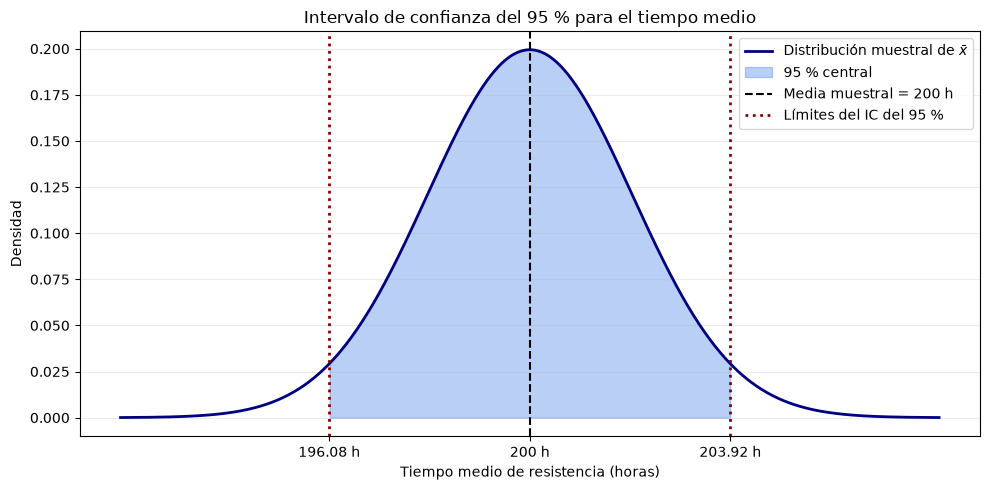

IC del 95 %: [196.08, 203.92] horas


In [1]:
import numpy as np
import matplotlib.pyplot as plt

media = 200
n = 64
sigma = 16
z_critico = 1.96
error_estandar = sigma / np.sqrt(n)
margen_error = z_critico * error_estandar
limite_inferior = media - margen_error
limite_superior = media + margen_error

# Densidad de la distribución muestral de la media, con límites del IC resaltados.
x = np.linspace(media - 4 * error_estandar, media + 4 * error_estandar, 600)
densidad = (1 / (error_estandar * np.sqrt(2 * np.pi))) * np.exp(
    -0.5 * ((x - media) / error_estandar) ** 2
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, densidad, color="navy", linewidth=2,
        label="Distribución muestral de $\\bar{x}$")
ax.fill_between(
    x, densidad, where=(x >= limite_inferior) & (x <= limite_superior),
    color="cornflowerblue", alpha=0.45, label="95 % central"
)
ax.axvline(media, color="black", linestyle="--", linewidth=1.5,
           label="Media muestral = 200 h")
ax.axvline(limite_inferior, color="darkred", linestyle=":", linewidth=2)
ax.axvline(limite_superior, color="darkred", linestyle=":", linewidth=2,
           label="Límites del IC del 95 %")
ax.set_title("Intervalo de confianza del 95 % para el tiempo medio")
ax.set_xlabel("Tiempo medio de resistencia (horas)")
ax.set_ylabel("Densidad")
ax.set_xticks([limite_inferior, media, limite_superior])
ax.set_xticklabels([
    f"{limite_inferior:.2f} h", f"{media:.0f} h", f"{limite_superior:.2f} h"
])
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print(f"IC del 95 %: [{limite_inferior:.2f}, {limite_superior:.2f}] horas")